# Teks — Klasifikasi dengan Prompt LLM Kecil (zero-shot / few-shot)
**Kapan dipakai:** label sedikit atau kategorinya baru, dan ingin model yang "membaca"
instruksi.

**Cara:** LLM lokal kecil (Qwen2.5-0.5B-Instruct, `pretrained/qwen_05b`) diberi instruksi +
beberapa contoh, lalu jawabannya (satu kata) dipetakan ke label. Tidak ada pelatihan.
LLM 0.5B lemah untuk tugas sulit, tapi cepat (GPU ±0.1 detik per teks) dan tanpa internet.

**Data demo:** SmSA (sentimen). Bandingkan dengan `text/zero_shot_nli` dan TF-IDF biasa.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import torch
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score
from sklearn.model_selection import train_test_split
from transformers import AutoModelForCausalLM, AutoTokenizer

## Konfigurasi
`LABEL_WORDS`: kata jawaban LLM (kiri) → label asli di data (kanan).

In [2]:
DATA_FOLDER = "Z:/GEMASTIK-DATABASE/data_latihan/text/sentiment"   # GANTI saat lomba
TRAIN_CSV = f"{DATA_FOLDER}/smsa_train.csv"
TEST_CSV = f"{DATA_FOLDER}/smsa_test.csv"
TEST_KEY_CSV = f"{DATA_FOLDER}/smsa_test_labels.csv"   # hanya ada di data latihan
LLM_FOLDER = "Z:/GEMASTIK-DATABASE/pretrained/qwen_05b"

TEXT_COL = "text"
TARGET = "label"
LABEL_WORDS = {"positif": "positive", "negatif": "negative", "netral": "neutral"}
FALLBACK_LABEL = "neutral"   # dipakai bila jawaban LLM di luar daftar
INSTRUCTION = ("Tentukan sentimen teks berikut. Jawab dengan SATU kata saja: "
               "positif, negatif, netral.")
N_VALIDATION = 300
BATCH_SIZE = 16
SEED = 42
DEVICE = "cpu"
if torch.cuda.is_available():
    DEVICE = "cuda"

## Baca data

In [3]:
train = pd.read_csv(TRAIN_CSV)
test = pd.read_csv(TEST_CSV)
print("train:", train.shape, "| test:", test.shape)
print(train[TARGET].value_counts())
train.head()

train: (5148, 3) | test: (1260, 2)
label
negative    2000
positive    2000
neutral     1148
Name: count, dtype: int64


,id,text,label
0,1,kenapa lumayan enak ? karena ada sushi lain ya...,negative
1,2,berarti staff nya anies yang tidak becus mengu...,negative
2,3,orang cina makanan legendaris sudah lama bange...,negative
3,4,"mental apa ini pak jokowi , bagaimana ini pak ...",negative
4,5,selama iblis binatang ini jadi kapolri jangan ...,negative


## Validasi kecil + 2 contoh pendek per kelas untuk few-shot

In [4]:
rest, validation = train_test_split(train, test_size=N_VALIDATION, stratify=train[TARGET],
                                    random_state=SEED)
short_texts = rest[rest[TEXT_COL].str.split().str.len() < 25]
examples = short_texts.groupby(TARGET).sample(2, random_state=SEED)
examples[[TEXT_COL, TARGET]]

,text,label
974,pagi sudah marah-marah karena pelayanan id cab...,negative
563,dosen itu tugas nya membimbing mahasiswa dalam...,negative
3060,"mengharukan , cerita anies baswedan saat berku...",neutral
2746,anas tinggalkan gus ipul pdip sebut angin puti...,neutral
4781,saya senang dengan prabowo karena beliau tidak...,positive
4696,penerbangan garuda indonesia adalah penerbanga...,positive


## Muat LLM + susun contoh percakapan
Tiap contoh = pesan "user" (instruksi + teks) lalu jawaban "assistant" (kata label).

In [5]:
tokenizer = AutoTokenizer.from_pretrained(LLM_FOLDER, padding_side="left")
llm = AutoModelForCausalLM.from_pretrained(LLM_FOLDER, dtype="auto")
llm = llm.to(DEVICE)
llm.eval()

word_for_label = {}
for word, label in LABEL_WORDS.items():
    word_for_label[label] = word

few_shot_messages = []
for text, label in zip(examples[TEXT_COL], examples[TARGET]):
    few_shot_messages.append({"role": "user", "content": INSTRUCTION + "\nTeks: " + text})
    few_shot_messages.append({"role": "assistant", "content": word_for_label[label]})
print(len(few_shot_messages), "pesan contoh")

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

12 pesan contoh


## Prompt + fungsi bertanya
Pilih SATU: few-shot (aktif) atau zero-shot (hapus `#`).
`ask` mengirim beberapa teks sekaligus dan mengembalikan jawaban mentah LLM.

In [6]:
prompt_start = few_shot_messages     # few-shot: 6 contoh di awal percakapan
# prompt_start = []                  # zero-shot: tanpa contoh


def ask(texts):
    prompts = []
    for text in texts:
        messages = prompt_start + [{"role": "user", "content": INSTRUCTION + "\nTeks: " + text}]
        prompts.append(tokenizer.apply_chat_template(messages, tokenize=False,
                                                     add_generation_prompt=True))
    encoded = tokenizer(prompts, return_tensors="pt", padding=True).to(DEVICE)
    with torch.no_grad():
        output = llm.generate(**encoded, max_new_tokens=4, do_sample=False)
    new_tokens = output[:, encoded["input_ids"].shape[1]:]   # buang bagian prompt
    return tokenizer.batch_decode(new_tokens, skip_special_tokens=True)


print(ask(["Makanannya enak sekali!", "Pelayanannya lambat dan kasar."]))

['positif', 'negatif']


## Ubah jawaban LLM menjadi label
Cukup cocokkan 4 huruf awal ("posi", "nega", "netr") supaya tahan variasi ejaan.

In [7]:
def to_label(reply):
    word = reply.strip().lower()
    for label_word, label in LABEL_WORDS.items():
        if word.startswith(label_word[:4]):
            return label
    return FALLBACK_LABEL


def predict_all(texts):
    labels = []
    for start in range(0, len(texts), BATCH_SIZE):
        for reply in ask(texts[start:start + BATCH_SIZE]):
            labels.append(to_label(reply))
    return labels


print(to_label(" Positif."), to_label("netral"), to_label("tidak tahu"))

positive neutral neutral


## Evaluasi di validasi

F1 macro: 0.6707
              precision    recall  f1-score   support

    negative       0.91      0.68      0.78       117
     neutral       0.47      0.43      0.45        67
    positive       0.69      0.90      0.78       116

    accuracy                           0.71       300
   macro avg       0.69      0.67      0.67       300
weighted avg       0.73      0.71      0.71       300



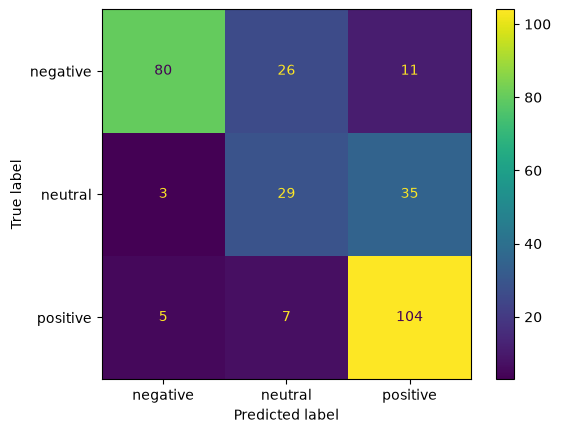

In [8]:
val_predictions = predict_all(list(validation[TEXT_COL]))
print("F1 macro:", round(f1_score(validation[TARGET], val_predictions, average="macro"), 4))
print(classification_report(validation[TARGET], val_predictions))
ConfusionMatrixDisplay.from_predictions(validation[TARGET], val_predictions)
plt.show()

## Prediksi test + submission (tanpa latih ulang)

In [9]:
predictions = predict_all(list(test[TEXT_COL]))

submission = pd.DataFrame()
submission["id"] = test["id"]
submission["label"] = predictions
submission.to_csv("submission.csv", index=False)
submission.head()

,id,label
0,100001,neutral
1,100002,negative
2,100003,positive
3,100004,positive
4,100005,negative


## Cek dengan kunci jawaban latihan
**HAPUS sel ini saat lomba**: file kunci hanya ada di data latihan.

In [10]:
test_key = pd.read_csv(TEST_KEY_CSV)["label"]
print("F1 macro test (kunci latihan):", round(f1_score(test_key, predictions, average="macro"), 4))

F1 macro test (kunci latihan): 0.6357
